# K-mer Sequence Classification

A first machine learning example for DNA: turn sequences into k-mer frequency vectors and train a classifier to tell where a short fragment comes from.

## The idea

Machine learning models need fixed-length numbers, but DNA fragments are strings. A **k-mer** is a substring of k bases, and counting how often each of the 4^k possible k-mers appears turns any fragment into a vector of the same length.

The task: given a 200-base fragment, decide whether it comes from the **chloroplast genome** (`NC_035298`) or from the **kainic acid gene cluster** (`MK312630`), two sequences of the red alga *Digenea simplex* used in the alignment quiz. The gene cluster is not part of the chloroplast genome, so the two have different base composition.

This is a small toy problem to show the workflow, not a biological result.

In [1]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
from Bio import SeqIO
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
chloroplast = SeqIO.read('../04-sequence-alignment/dataset/NC_035298.fasta', 'fasta').seq
cluster = SeqIO.read('../04-sequence-alignment/dataset/MK312630.fasta', 'fasta').seq

print(f'Chloroplast genome: {len(chloroplast):,} bases')
print(f'Gene cluster:       {len(cluster):,} bases')

Chloroplast genome: 174,848 bases
Gene cluster:       12,381 bases


## Cutting the sequences into fragments

Each sequence is cut into consecutive, non-overlapping fragments of 200 bases. Fragments that contain anything other than A, C, G or T are dropped.

In [3]:
FRAGMENT_SIZE = 200


def fragments(seq, size=FRAGMENT_SIZE):
    pieces = (str(seq[i:i + size]).upper() for i in range(0, len(seq) - size + 1, size))
    return [p for p in pieces if set(p) <= set('ACGT')]


chloro_frags = fragments(chloroplast)
cluster_frags = fragments(cluster)
print(f'Chloroplast fragments: {len(chloro_frags)}')
print(f'Gene cluster fragments: {len(cluster_frags)}')

Chloroplast fragments: 874
Gene cluster fragments: 61


## Train and test split

The first 70% of each sequence is used for training and the last 30% for testing. Splitting by position, instead of shuffling, keeps neighbouring fragments out of the test set, so the model can't score well just because it has already seen the surrounding sequence.

Chloroplast fragments are far more numerous, so the evaluation uses **balanced accuracy** (the average of the recall on each class) and the model weights the classes equally.

In [4]:
def split_by_position(frags, train_share=0.7):
    cut = int(len(frags) * train_share)
    return frags[:cut], frags[cut:]


chloro_train, chloro_test = split_by_position(chloro_frags)
cluster_train, cluster_test = split_by_position(cluster_frags)

train_frags = chloro_train + cluster_train
y_train = np.array([0] * len(chloro_train) + [1] * len(cluster_train))
test_frags = chloro_test + cluster_test
y_test = np.array([0] * len(chloro_test) + [1] * len(cluster_test))

print(f'Train: {len(chloro_train)} chloroplast + {len(cluster_train)} cluster fragments')
print(f'Test:  {len(chloro_test)} chloroplast + {len(cluster_test)} cluster fragments')

Train: 611 chloroplast + 42 cluster fragments
Test:  263 chloroplast + 19 cluster fragments


## K-mer features

`kmer_features` counts every overlapping k-mer in a fragment and divides by the total, giving frequencies that sum to 1. With k = 3 there are 4^3 = 64 features, one per codon-sized word.

In [5]:
def kmer_features(frags, k):
    index = {''.join(p): i for i, p in enumerate(product('ACGT', repeat=k))}
    X = np.zeros((len(frags), len(index)))
    for row, frag in enumerate(frags):
        for i in range(len(frag) - k + 1):
            X[row, index[frag[i:i + k]]] += 1
    return X / X.sum(axis=1, keepdims=True), list(index)


def make_model():
    return make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=2000))

## Baseline: GC content only

Before using k-mers, check how far one simple number gets. GC content (the share of G and C) is a single feature per fragment.

In [6]:
def gc_content(frags):
    return np.array([[(f.count('G') + f.count('C')) / len(f)] for f in frags])


baseline = make_model().fit(gc_content(train_frags), y_train)
baseline_score = balanced_accuracy_score(y_test, baseline.predict(gc_content(test_frags)))
print(f'GC content only -> balanced accuracy {baseline_score:.3f}')

GC content only -> balanced accuracy 0.630


## How much does k matter?

Train one model for each k from 1 to 5. k = 1 is just the frequency of each single base, and the number of features grows four times with every step.

k=1 (   4 features) -> balanced accuracy 0.527
k=2 (  16 features) -> balanced accuracy 0.785
k=3 (  64 features) -> balanced accuracy 0.811
k=4 ( 256 features) -> balanced accuracy 0.844
k=5 (1024 features) -> balanced accuracy 0.677


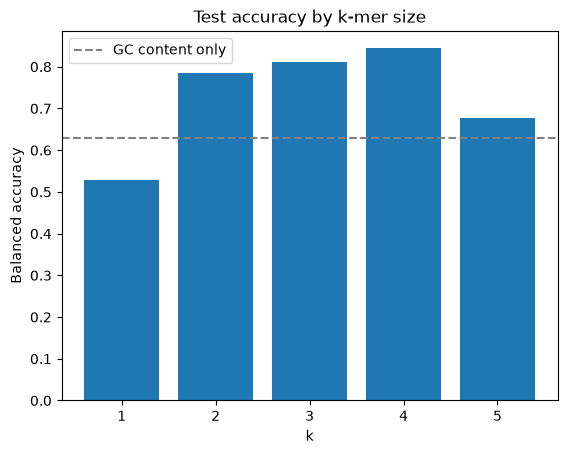

In [7]:
results = {}
for k in range(1, 6):
    X_train, _ = kmer_features(train_frags, k)
    X_test, _ = kmer_features(test_frags, k)
    model = make_model().fit(X_train, y_train)
    results[k] = balanced_accuracy_score(y_test, model.predict(X_test))
    print(f'k={k} ({4 ** k:>4} features) -> balanced accuracy {results[k]:.3f}')

plt.bar([str(k) for k in results], list(results.values()))
plt.axhline(baseline_score, color='gray', linestyle='--', label='GC content only')
plt.xlabel('k')
plt.ylabel('Balanced accuracy')
plt.title('Test accuracy by k-mer size')
plt.legend()
plt.show()

## Looking inside the k = 3 model

The confusion matrix shows the mistakes (rows are the true class, columns the prediction). The logistic regression coefficients show which 3-mers push a fragment towards each class.

In [8]:
K = 3
X_train, names = kmer_features(train_frags, K)
X_test, _ = kmer_features(test_frags, K)
model = make_model().fit(X_train, y_train)
pred = model.predict(X_test)

print('Confusion matrix (rows: true class, columns: predicted)')
print('               chloroplast  gene cluster')
matrix = confusion_matrix(y_test, pred)
print(f'chloroplast    {matrix[0, 0]:>10}  {matrix[0, 1]:>12}')
print(f'gene cluster   {matrix[1, 0]:>10}  {matrix[1, 1]:>12}')

Confusion matrix (rows: true class, columns: predicted)
               chloroplast  gene cluster
chloroplast           233            30
gene cluster            5            14


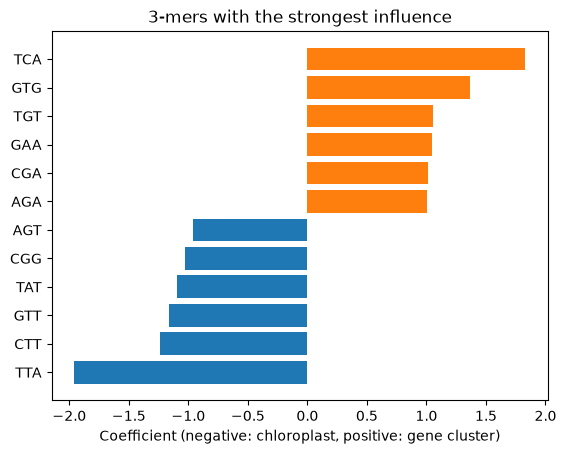

In [9]:
coefs = model[-1].coef_[0]
order = np.argsort(coefs)
picked = list(order[:6]) + list(order[-6:])

colors = ['tab:blue' if coefs[i] < 0 else 'tab:orange' for i in picked]
plt.barh([names[i] for i in picked], [coefs[i] for i in picked], color=colors)
plt.xlabel('Coefficient (negative: chloroplast, positive: gene cluster)')
plt.title('3-mers with the strongest influence')
plt.show()

## Limits

- The gene cluster gives only a few dozen fragments, so the test set for that class is tiny and the scores move noticeably with the fragment size or the split.
- Both sequences come from one species, so the model mostly learns differences in base composition and codon usage, not anything specific to the genes.
- Real projects use far more data, several organisms and cross-validation. The same k-mer features also feed other models such as random forests or small neural networks.